In [3]:
from pathlib import Path
import pandas as pd

data_dir = Path("A3/dataset")

ratings = pd.read_csv("/Users/aryamanbahl/IIITH/m26/data_analytics/assignments/M26_Data_Analytics_I_Assignment_1/A3/dataset/ratings.csv")
movies = pd.read_csv("/Users/aryamanbahl/IIITH/m26/data_analytics/assignments/M26_Data_Analytics_I_Assignment_1/A3/dataset/movies.csv")
tags = pd.read_csv("/Users/aryamanbahl/IIITH/m26/data_analytics/assignments/M26_Data_Analytics_I_Assignment_1/A3/dataset/tags.csv")
links = pd.read_csv("/Users/aryamanbahl/IIITH/m26/data_analytics/assignments/M26_Data_Analytics_I_Assignment_1/A3/dataset/links.csv", dtype={"imdbId": "string"})

In [4]:
for name, data in {
    "ratings": ratings,
    "movies": movies,
    "tags": tags,
    "links": links,
}.items():
    print(f"\n{name}: {data.shape[0]:,} rows, {data.shape[1]} columns")
    display(data.head())


ratings: 100,836 rows, 4 columns


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931



movies: 9,742 rows, 3 columns


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy



tags: 3,683 rows, 4 columns


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200



links: 9,742 rows, 3 columns


,movieId,imdbId,tmdbId
0,1,0114709,862.0
1,2,0113497,8844.0
2,3,0113228,15602.0
3,4,0114885,31357.0
4,5,0113041,11862.0


In [5]:
ratings.info()

display(ratings.isna().sum().rename("missing"))
display(movies.isna().sum().rename("missing"))

print("Duplicate user–movie ratings:",
      ratings.duplicated(["userId", "movieId"]).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


userId       0
movieId      0
rating       0
timestamp    0
Name: missing, dtype: int64

movieId    0
title      0
genres     0
Name: missing, dtype: int64

Duplicate user–movie ratings: 0


In [6]:
display(ratings["rating"].value_counts().sort_index().rename("count"))

ratings_per_user = ratings.groupby("userId")["movieId"].nunique()
display(ratings_per_user.describe().rename("movies rated per user"))

display(movies["genres"].str.split("|").explode().value_counts().head(10))

rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
Name: movies rated per user, dtype: float64

genres
Drama        4361
Comedy       3756
Thriller     1894
Action       1828
Romance      1596
Adventure    1263
Crime        1199
Sci-Fi        980
Horror        978
Fantasy       779
Name: count, dtype: int64

In [7]:
ratings["liked"] = (ratings["rating"] >= 3.0).astype("int8")

liked = ratings.loc[
    ratings["liked"] == 1,
    ["userId", "movieId", "liked"]
].copy()

liked = liked.drop_duplicates(["userId", "movieId"])

display(liked.head())
print("Positive interactions:", len(liked))

,userId,movieId,liked
0,1,1,1
1,1,3,1
2,1,6,1
3,1,47,1
4,1,50,1


Positive interactions: 81763


In [8]:
liked_counts = liked.groupby("userId")["movieId"].transform("nunique")
liked = liked.loc[liked_counts >= 5].copy()

print("Retained users:", liked["userId"].nunique())
print("Retained movies:", liked["movieId"].nunique())
print("Retained interactions:", len(liked))

Retained users: 608
Retained movies: 8452
Retained interactions: 81759


In [9]:
liked_movies = liked.merge(
    movies,
    on="movieId",
    how="left",
    validate="many_to_one"
)

display(liked_movies.head(10))

,userId,movieId,liked,title,genres
0,1,1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,1,Grumpier Old Men (1995),Comedy|Romance
2,1,6,1,Heat (1995),Action|Crime|Thriller
3,1,47,1,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,1,"Usual Suspects, The (1995)",Crime|Mystery|Thriller
5,1,70,1,From Dusk Till Dawn (1996),Action|Comedy|Horror|Thriller
6,1,101,1,Bottle Rocket (1996),Adventure|Comedy|Crime|Romance
7,1,110,1,Braveheart (1995),Action|Drama|War
8,1,151,1,Rob Roy (1995),Action|Drama|Romance|War
9,1,157,1,Canadian Bacon (1995),Comedy|War


In [10]:
baskets = (
    liked.groupby("userId")["movieId"]
    .agg(list)
    .rename("movieIds")
    .reset_index()
)

baskets["basket_size"] = baskets["movieIds"].str.len()

display(baskets.head())
display(baskets["basket_size"].describe())

assert baskets["basket_size"].min() >= 5

,userId,movieIds,basket_size
0,1,"[1, 3, 6, 47, 50, 70, 101, 110, 151, 157, 163,...",226
1,2,"[318, 333, 1704, 3578, 6874, 8798, 46970, 4851...",27
2,3,"[849, 1275, 1371, 1587, 2288, 2851, 3024, 3703...",18
3,4,"[21, 45, 52, 58, 106, 125, 162, 171, 176, 215,...",167
4,5,"[1, 21, 34, 36, 39, 50, 58, 110, 150, 153, 232...",40


count     608.000000
mean      134.472039
std       202.546871
min        10.000000
25%        31.000000
50%        61.500000
75%       146.500000
max      2117.000000
Name: basket_size, dtype: float64

In [ ]:
user_movie = pd.crosstab(
    liked["userId"],
    liked["movieId"]
).astype("int8")

display(user_movie.iloc[:5, :10])
print("Matrix shape:", user_movie.shape)

movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,1,0,1,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0
5,1,0,0,0,0,0,0,0,0,0


Matrix shape: (608, 8452)


In [15]:
%run preprocess.py

Users: 608
Training transactions: 486
Test transactions: 122


In [18]:
from pathlib import Path
import pandas as pd

output_dir = Path("processed")

transactions = pd.read_json(output_dir / "transactions.json")
train = pd.read_json(output_dir / "train.json")
test = pd.read_json(output_dir / "test.json")

display(transactions.head())
display(transactions["movieIds"].str.len().describe())

,userId,movieIds
0,1,"[1, 3, 6, 47, 50, 70, 101, 110, 151, 157, 163,..."
1,2,"[318, 333, 1704, 3578, 6874, 8798, 46970, 4851..."
2,3,"[849, 1275, 1371, 1587, 2288, 2851, 3024, 3703..."
3,4,"[21, 45, 52, 58, 106, 125, 162, 171, 176, 215,..."
4,5,"[1, 21, 34, 36, 39, 50, 58, 110, 150, 153, 232..."


count     608.000000
mean      134.472039
std       202.546871
min        10.000000
25%        31.000000
50%        61.500000
75%       146.500000
max      2117.000000
Name: movieIds, dtype: float64

In [19]:
assert transactions["userId"].is_unique
assert transactions["movieIds"].str.len().min() >= 5
assert all(len(items) == len(set(items)) for items in transactions["movieIds"])

assert set(train["userId"]).isdisjoint(test["userId"])
assert set(train["userId"]) | set(test["userId"]) == set(transactions["userId"])

print(f"Total: {len(transactions)}, train: {len(train)}, test: {len(test)}")

Total: 608, train: 486, test: 122


In [20]:
display(transactions.head())

basket_sizes = transactions["movieIds"].str.len()
train_sizes = train["movieIds"].str.len()
test_sizes = test["movieIds"].str.len()

display(pd.DataFrame({
    "all": basket_sizes.describe(),
    "train": train_sizes.describe(),
    "test": test_sizes.describe(),
}))

,userId,movieIds
0,1,"[1, 3, 6, 47, 50, 70, 101, 110, 151, 157, 163,..."
1,2,"[318, 333, 1704, 3578, 6874, 8798, 46970, 4851..."
2,3,"[849, 1275, 1371, 1587, 2288, 2851, 3024, 3703..."
3,4,"[21, 45, 52, 58, 106, 125, 162, 171, 176, 215,..."
4,5,"[1, 21, 34, 36, 39, 50, 58, 110, 150, 153, 232..."


,all,train,test
count,608.000000,486.000000,122.000000
mean,134.472039,136.008230,128.352459
std,202.546871,189.980889,247.159463
min,10.000000,11.000000,10.000000
25%,31.000000,32.250000,27.000000
50%,61.500000,66.000000,50.500000
75%,146.500000,158.000000,134.750000
max,2117.000000,1750.000000,2117.000000


In [21]:
example_user = train.iloc[0]

print("User:", example_user["userId"])
print("Basket size:", len(example_user["movieIds"]))

display(
    movies.loc[
        movies["movieId"].isin(example_user["movieIds"]),
        ["movieId", "title", "genres"]
    ].head(10)
)

User: 110
Basket size: 46


,movieId,title,genres
43,47,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
97,110,Braveheart (1995),Action|Drama|War
98,111,Taxi Driver (1976),Crime|Drama|Thriller
198,232,Eat Drink Man Woman (Yin shi nan nu) (1994),Comedy|Drama|Romance
257,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
461,527,Schindler's List (1993),Drama|War
474,541,Blade Runner (1982),Action|Sci-Fi|Thriller
520,608,Fargo (1996),Comedy|Crime|Drama|Thriller
613,778,Trainspotting (1996),Comedy|Crime|Drama
691,909,"Apartment, The (1960)",Comedy|Drama|Romance


In [24]:
from matplotlib import pyplot as plt

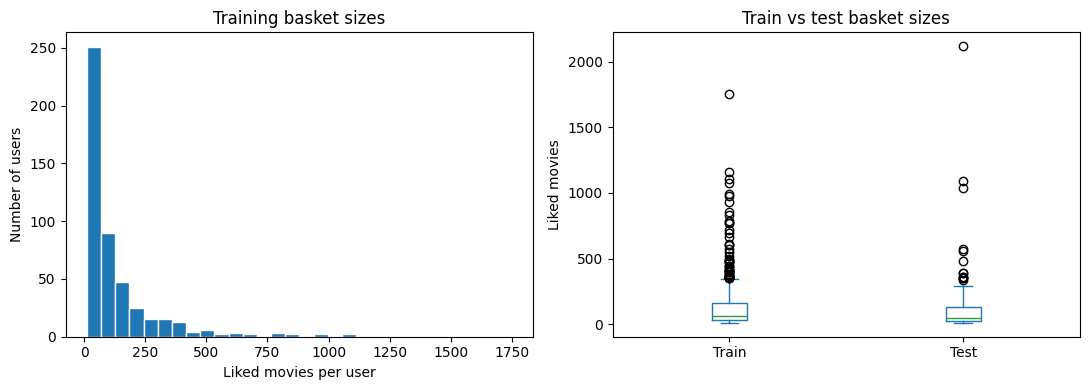

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

train_sizes.plot.hist(bins=30, ax=axes[0], edgecolor="white")
axes[0].set(
    title="Training basket sizes",
    xlabel="Liked movies per user",
    ylabel="Number of users",
)

pd.DataFrame({
    "Train": train_sizes,
    "Test": test_sizes,
}).plot.box(ax=axes[1])

axes[1].set(title="Train vs test basket sizes", ylabel="Liked movies")

plt.tight_layout()
plt.show()

In [26]:
movie_counts = train["movieIds"].explode().value_counts()

popularity = (
    movie_counts.rename_axis("movieId")
    .reset_index(name="users")
    .merge(movies[["movieId", "title"]], on="movieId")
)

popularity["user_percent"] = 100 * popularity["users"] / len(train)
display(popularity.head(10))

,movieId,users,title,user_percent
0,356,258,Forrest Gump (1994),53.086420
1,318,253,"Shawshank Redemption, The (1994)",52.057613
2,296,232,Pulp Fiction (1994),47.736626
3,593,219,"Silence of the Lambs, The (1991)",45.061728
4,2571,212,"Matrix, The (1999)",43.621399
5,260,189,Star Wars: Episode IV - A New Hope (1977),38.888889
6,480,181,Jurassic Park (1993),37.242798
7,110,178,Braveheart (1995),36.625514
8,589,172,Terminator 2: Judgment Day (1991),35.390947
9,2959,167,Fight Club (1999),34.362140


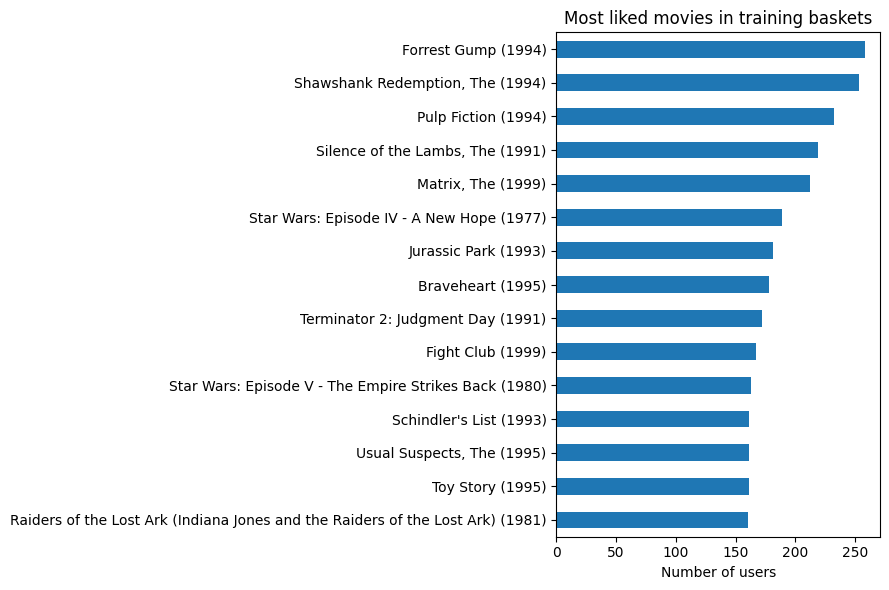

In [27]:
popularity.head(15).sort_values("users").plot.barh(
    x="title",
    y="users",
    figsize=(9, 6),
    legend=False,
)

plt.title("Most liked movies in training baskets")
plt.xlabel("Number of users")
plt.ylabel("")
plt.tight_layout()
plt.show()

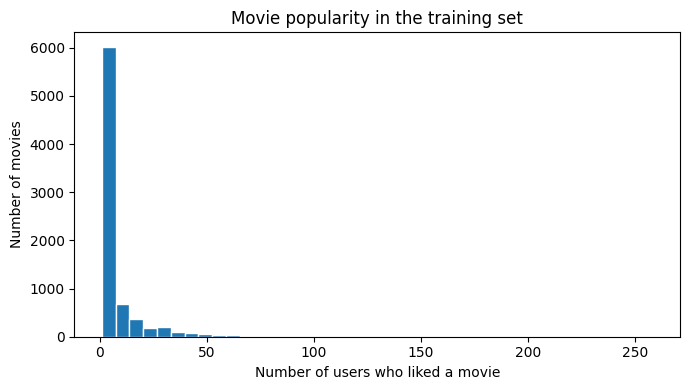

Movies liked by just one training user: 3072


In [28]:
movie_counts.plot.hist(bins=40, figsize=(7, 4), edgecolor="white")

plt.title("Movie popularity in the training set")
plt.xlabel("Number of users who liked a movie")
plt.ylabel("Number of movies")
plt.tight_layout()
plt.show()

print("Movies liked by just one training user:", movie_counts.eq(1).sum())

In [29]:
train_movies = set(train["movieIds"].explode())
test_movies = set(test["movieIds"].explode())

print("Distinct training movies:", len(train_movies))
print("Distinct test movies:", len(test_movies))
print("Test movies absent from training:", len(test_movies - train_movies))

Distinct training movies: 7894
Distinct test movies: 4303
Test movies absent from training: 558


In [30]:
import pandas as pd

train = pd.read_json("processed/train.json")

# One row per user–movie interaction.
interactions = train.explode("movieIds")

# True means the movie appears in that user's basket.
train_matrix = pd.crosstab(
    interactions["userId"],
    interactions["movieIds"]
).gt(0)

print("Training matrix:", train_matrix.shape)
display(train_matrix.iloc[:5, :10])

Training matrix: (486, 7894)


movieIds,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,True,False,True,False,False,True,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
6,False,True,True,True,True,True,True,True,False,True
7,True,False,False,False,False,False,False,False,False,False
